In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")
df.head()

Libraries imported successfully!


,date,temperature_c,data_type
0,2018-01-01,11.7,simulated_classroom_data
1,2018-01-02,10.4,simulated_classroom_data
2,2018-01-03,16.9,simulated_classroom_data
3,2018-01-04,14.8,simulated_classroom_data
4,2018-01-05,7.9,simulated_classroom_data


In [63]:
import pandas as pd

df = pd.read_csv("temperature_forecasting_dataset.csv")

# Remove extra spaces and make column names lowercase
df.columns = df.columns.str.strip().str.lower()

print("Columns:", df.columns.tolist())
display(df.head())

Columns: ['date', 'temperature_c', 'data_type']


,date,temperature_c,data_type
0,2018-01-01,11.7,simulated_classroom_data
1,2018-01-02,10.4,simulated_classroom_data
2,2018-01-03,16.9,simulated_classroom_data
3,2018-01-04,14.8,simulated_classroom_data
4,2018-01-05,7.9,simulated_classroom_data


In [39]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Date conversion completed.")
print(df[["date", "temperature_c"]].head())

Date conversion completed.
        date  temperature_c
0 2018-01-01           11.7
1 2018-01-02           10.4
2 2018-01-03           16.9
3 2018-01-04           14.8
4 2018-01-05            7.9


In [30]:
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print(df.columns.tolist())
df.dtypes

Dataset shape: (1826, 1)
Total rows: 1826
Total columns: 1
['temperature_c']


temperature_c    float64
dtype: object

In [33]:
df.describe(include="all")
df.isnull().sum()
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1479


In [35]:
if "data_type" in df.columns:
    print(df["data_type"].nunique(), "unique value in data_type")
    df = df.drop(columns=["data_type"])
df.head()

,temperature_c
date,
2018-01-01,11.7
2018-01-02,10.4
2018-01-03,16.9
2018-01-04,14.8
2018-01-05,7.9


In [40]:
clean_df = df.copy()

clean_df["temperature_c"] = pd.to_numeric(
    clean_df["temperature_c"], errors="coerce"
)

clean_df = clean_df.dropna(
    subset=["date", "temperature_c"]
)

clean_df = clean_df.drop_duplicates()
clean_df = clean_df.sort_values("date").reset_index(drop=True)

print("Cleaning completed!")
print("Dataset shape:", clean_df.shape)

Cleaning completed!
Dataset shape: (1826, 3)


In [22]:
df["temperature_c"] = df["temperature_c"].interpolate(method="time")
print("Missing now:", df["temperature_c"].isna().sum())

Missing now: 0


In [41]:
clean_df["day"] = clean_df["date"].dt.day
clean_df["month"] = clean_df["date"].dt.month
clean_df["year"] = clean_df["date"].dt.year
clean_df["day_of_year"] = clean_df["date"].dt.dayofyear
clean_df["day_of_week"] = clean_df["date"].dt.dayofweek

clean_df.head()

,date,temperature_c,data_type,day,month,year,day_of_year,day_of_week
0,2018-01-01,11.7,simulated_classroom_data,1,1,2018,1,0
1,2018-01-02,10.4,simulated_classroom_data,2,1,2018,2,1
2,2018-01-03,16.9,simulated_classroom_data,3,1,2018,3,2
3,2018-01-04,14.8,simulated_classroom_data,4,1,2018,4,3
4,2018-01-05,7.9,simulated_classroom_data,5,1,2018,5,4


In [42]:
clean_df["previous_day_temp"] = clean_df["temperature_c"].shift(1)

clean_df.head()

,date,temperature_c,data_type,day,month,year,day_of_year,day_of_week,previous_day_temp
0,2018-01-01,11.7,simulated_classroom_data,1,1,2018,1,0,NaN
1,2018-01-02,10.4,simulated_classroom_data,2,1,2018,2,1,11.7
2,2018-01-03,16.9,simulated_classroom_data,3,1,2018,3,2,10.4
3,2018-01-04,14.8,simulated_classroom_data,4,1,2018,4,3,16.9
4,2018-01-05,7.9,simulated_classroom_data,5,1,2018,5,4,14.8


In [43]:
print("Updated columns:")
print(clean_df.columns.tolist())

clean_df.head(10)

Updated columns:
['date', 'temperature_c', 'data_type', 'day', 'month', 'year', 'day_of_year', 'day_of_week', 'previous_day_temp']


,date,temperature_c,data_type,day,month,year,day_of_year,day_of_week,previous_day_temp
0,2018-01-01,11.7,simulated_classroom_data,1,1,2018,1,0,NaN
1,2018-01-02,10.4,simulated_classroom_data,2,1,2018,2,1,11.7
2,2018-01-03,16.9,simulated_classroom_data,3,1,2018,3,2,10.4
3,2018-01-04,14.8,simulated_classroom_data,4,1,2018,4,3,16.9
4,2018-01-05,7.9,simulated_classroom_data,5,1,2018,5,4,14.8
5,2018-01-06,10.7,simulated_classroom_data,6,1,2018,6,5,7.9
6,2018-01-07,13.7,simulated_classroom_data,7,1,2018,7,6,10.7
7,2018-01-08,10.5,simulated_classroom_data,8,1,2018,8,0,13.7
8,2018-01-09,12.4,simulated_classroom_data,9,1,2018,9,1,10.5
9,2018-01-10,11.8,simulated_classroom_data,10,1,2018,10,2,12.4


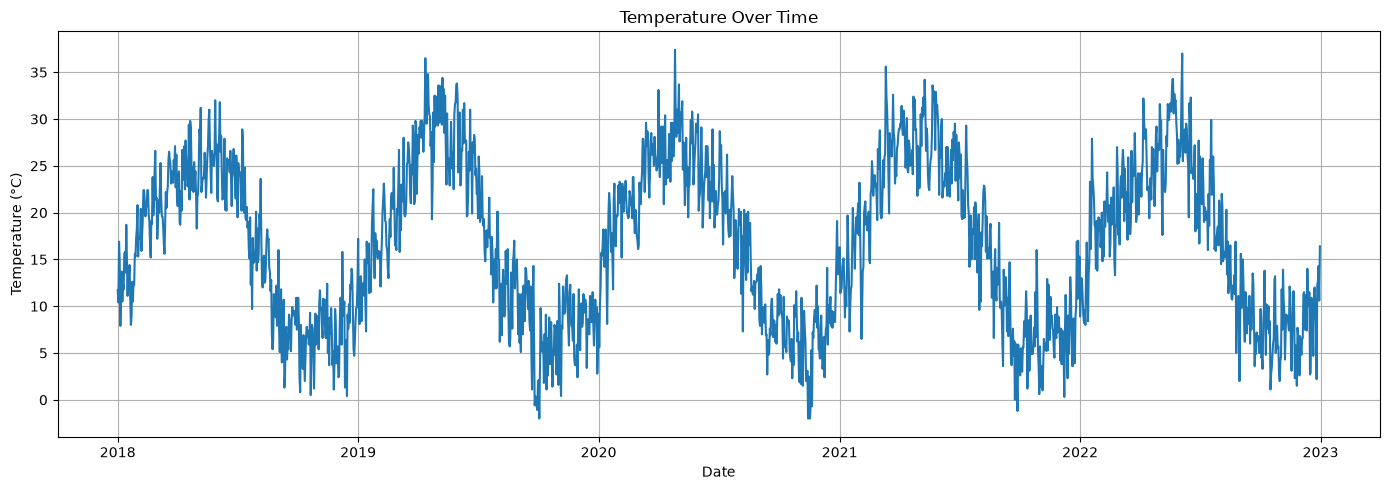

In [45]:
plt.figure(figsize=(14, 5))

plt.plot(
    clean_df["date"],
    clean_df["temperature_c"]
)

plt.title("Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [46]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

In [ ]:
clean_df = clean_df.sort_values("date").reset_index(drop=True)
rnn_df = clean_df[["date", "temperature_c"]].copy()


display(rnn_df.head())

print("Total observations:", len(rnn_df))
print("Missing values:\n", rnn_df.isnull().sum())
print("Duplicate dates:", rnn_df["date"].duplicated().sum())

,date,temperature_c
0,2018-01-01,11.7
1,2018-01-02,10.4
2,2018-01-03,16.9
3,2018-01-04,14.8
4,2018-01-05,7.9


Total observations: 1826
Missing values:
 date             0
temperature_c    0
dtype: int64
Duplicate dates: 0


In [48]:
sequence_length = 7

print("Input sequence length:", sequence_length)
print("Prediction target: Temperature of the next day")

Input sequence length: 7
Prediction target: Temperature of the next day


In [ ]:
temperatures = rnn_df["temperature_c"].to_numpy().reshape(-1, 1)
split_index = int(len(temperatures) * 0.80)

train_temperatures = temperatures[:split_index]

print("Training observations:", len(train_temperatures))
print("Testing observations:", len(temperatures) - split_index)
print("Training ends:", rnn_df["date"].iloc[split_index - 1])
print("Testing starts:", rnn_df["date"].iloc[split_index])

Training observations: 1460
Testing observations: 366
Training ends: 2021-12-30 00:00:00
Testing starts: 2021-12-31 00:00:00


In [ ]:
scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(train_temperatures)
scaled_temperatures = scaler.transform(temperatures)

print("Original temperature examples:")
print(temperatures[:5].flatten())

print("\nScaled temperature examples:")
print(scaled_temperatures[:5].flatten())

Original temperature examples:
[11.7 10.4 16.9 14.8  7.9]

Scaled temperature examples:
[0.34771574 0.31472081 0.47969543 0.42639594 0.25126904]


In [ ]:
X = []
y = []
target_indices = []

for i in range(sequence_length, len(scaled_temperatures)):
    X.append(scaled_temperatures[i - sequence_length:i])
    y.append(scaled_temperatures[i, 0])

    target_indices.append(i)

X = np.array(X)
y = np.array(y)
target_indices = np.array(target_indices)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (1819, 7, 1)
y shape: (1819,)


In [52]:
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train = X[train_mask]
y_train = y[train_mask]

X_test = X[test_mask]
y_test = y[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1453, 7, 1)
y_train: (1453,)
X_test: (366, 7, 1)
y_test: (366,)


In [53]:
sample_input = X_train[0]
sample_target = y_train[0]

print("Seven scaled input temperatures:")
print(sample_input.flatten())

print("\nScaled target temperature:")
print(sample_target)

print("\nActual target date:")
print(rnn_df["date"].iloc[sequence_length])

Seven scaled input temperatures:
[0.34771574 0.31472081 0.47969543 0.42639594 0.25126904 0.32233503
 0.39847716]

Scaled target temperature:
0.31725888324873097

Actual target date:
2018-01-08 00:00:00


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import mean_absolute_error, mean_squared_error


TensorFlow version: 2.22.0-rc0


In [55]:
model = Sequential([
    SimpleRNN(
        64,
        activation="tanh",
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error",
    metrics=["mae"]
)

model.summary()

c:\Users\pc\OneDrive\Desktop\RNN_Based(Model)\rnn_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,337 (24.75 KB)

 Trainable params: 6,337 (24.75 KB)

 Non-trainable params: 0 (0.00 B)

In [56]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("RNN training completed!")

Epoch 1/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0238 - mae: 0.1253 - val_loss: 0.0073 - val_mae: 0.0675
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0111 - mae: 0.0827 - val_loss: 0.0071 - val_mae: 0.0685
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0093 - mae: 0.0766 - val_loss: 0.0071 - val_mae: 0.0681
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0096 - mae: 0.0783 - val_loss: 0.0067 - val_mae: 0.0658
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0100 - mae: 0.0796 - val_loss: 0.0077 - val_mae: 0.0714
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - mae: 0.0774 - val_loss: 0.0080 - val_mae: 0.0728
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0091 - mae: 0.0763 - val_loss: 0.0081 - val_mae: 0.0729
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0093 - mae: 0.0764 - val_loss: 0.0081 - val_mae: 0.0733
Epoch 9/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.00

In [ ]:
y_pred_scaled = model.predict(X_test, verbose=0)
y_pred = scaler.inverse_transform(y_pred_scaled).flatten()
y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 366


In [59]:
mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

print(f"MAE:  {mae:.3f} °C")
print(f"RMSE: {rmse:.3f} °C")

MAE:  2.646 °C
RMSE: 3.410 °C


In [60]:
results = pd.DataFrame({
    "Date": rnn_df["date"].iloc[target_indices[test_mask]].to_numpy(),
    "Actual_Temperature": y_actual,
    "Predicted_Temperature": y_pred
})

display(results.head(15))

,Date,Actual_Temperature,Predicted_Temperature
0,2021-12-31,15.3,12.205111
1,2022-01-01,8.9,13.521254
2,2022-01-02,11.0,11.642492
3,2022-01-03,13.0,12.270204
4,2022-01-04,12.4,12.041662
5,2022-01-05,10.6,13.040151
6,2022-01-06,8.9,11.077230
7,2022-01-07,8.2,10.527751
8,2022-01-08,9.6,9.344918
9,2022-01-09,8.0,9.735767


In [66]:
sample = results.iloc[4]

print("Date:", sample["Date"])
print(f"Actual temperature: {sample['Actual_Temperature']:.2f} °C")
print(f"Predicted temperature: {sample['Predicted_Temperature']:.2f} °C")

error = abs(
    sample["Actual_Temperature"] - sample["Predicted_Temperature"]
)

print(f"Absolute prediction error: {error:.2f} °C")

Date: 2022-01-04 00:00:00
Actual temperature: 12.40 °C
Predicted temperature: 12.04 °C
Absolute prediction error: 0.36 °C


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    LSTM(64, activation='tanh', return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

c:\Users\pc\OneDrive\Desktop\RNN_Based(Model)\rnn_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

In [68]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("LSTM training completed!")

Epoch 1/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - loss: 0.0845 - mae: 0.2195 - val_loss: 0.0117 - val_mae: 0.0888
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0125 - mae: 0.0880 - val_loss: 0.0094 - val_mae: 0.0780
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0105 - mae: 0.0808 - val_loss: 0.0081 - val_mae: 0.0717
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0097 - mae: 0.0780 - val_loss: 0.0078 - val_mae: 0.0706
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - mae: 0.0762 - val_loss: 0.0078 - val_mae: 0.0703
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0096 - mae: 0.0781 - val_loss: 0.0091 - val_mae: 0.0764
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0092 - mae: 0.0762 - val_loss: 0.0077 - val_mae: 0.0700
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0088 - mae: 0.0747 - val_loss: 0.0076 - val_mae: 0.0696
Epoch 9/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.00

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    GRU(64, activation='tanh', return_sequences=False, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

model.summary()

c:\Users\pc\OneDrive\Desktop\RNN_Based(Model)\rnn_env\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        12,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,977 (58.50 KB)

 Trainable params: 14,977 (58.50 KB)

 Non-trainable params: 0 (0.00 B)

In [77]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("GRU training completed!")

Epoch 1/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - loss: 0.0644 - mae: 0.1910 - val_loss: 0.0136 - val_mae: 0.0967
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0124 - mae: 0.0882 - val_loss: 0.0092 - val_mae: 0.0790
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0092 - mae: 0.0762 - val_loss: 0.0072 - val_mae: 0.0679
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0086 - mae: 0.0739 - val_loss: 0.0069 - val_mae: 0.0656
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0080 - mae: 0.0715 - val_loss: 0.0068 - val_mae: 0.0657
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0084 - mae: 0.0726 - val_loss: 0.0072 - val_mae: 0.0685
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0081 - mae: 0.0720 - val_loss: 0.0068 - val_mae: 0.0655
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0080 - mae: 0.0714 - val_loss: 0.0068 - val_mae: 0.0655
Epoch 9/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.00